# Week 9 · Day 1 — Correlation and linear regression: HW 9.1 starter

Nur Finance. Part 0 is a walk-through (run and read). Then **five functions**, each followed by an **assert cell**; a red cell is a function you have not written yet. Then **HW 9.1**: the payment rule for Consumer loans, and three sentences for the affordability team. Use `numpy` and `pandas` only inside the functions (no `corr`, `polyfit` or `linregress` there).

In [1]:
from pathlib import Path
import hashlib
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
# this notebook lives in data/python/week9/, so "../.." is the data/ folder
DATA = Path("../..")
con = sqlite3.connect(DATA / "raw" / "nur.db")


def check(value, fingerprints, dp=0):
    """Right or wrong without showing the answer: the rounded value's fingerprint must be one of the expected ones."""
    fp = hashlib.sha256(f"nur-w9:{round(float(value), dp):.{dp}f}".encode()).hexdigest()[:12]
    assert fp in fingerprints, "not yet: this result is not the expected one — check your function and run again"

In [2]:
# The loans, with principal in millions of soum and the monthly payment in thousands (run, do not edit)
loans = pd.read_sql("SELECT loan_id, product_id, principal, term_months, monthly_payment, status FROM loans", con)
loans["pm"] = loans["principal"] / 1e6
loans["pay_k"] = loans["monthly_payment"] / 1e3
auto = loans[loans["product_id"] == 4].copy()
cons = loans[loans["product_id"] == 2].copy()
assert len(loans) == 7828 and len(auto) == 391 and len(cons) == 2418
print(len(loans), len(auto), len(cons))

7828 391 2418


## 0. Walk-through — the Auto line (the page's section 1)
391 Auto loans: payment against principal, the least-squares line, R², and the residuals by term.

slope 41.49 thousand soum per 1 m, intercept -12.1, r 0.8926, R² 0.7967


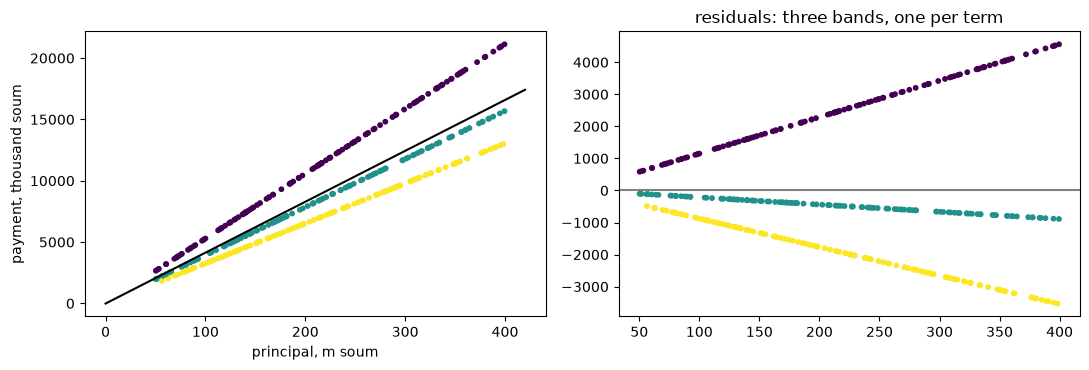

term_months
24    2480.0
36    -467.0
48   -1952.0
Name: res, dtype: float64

In [3]:
b, a = np.polyfit(auto["pm"], auto["pay_k"], 1)
r = np.corrcoef(auto["pm"], auto["pay_k"])[0, 1]
print(f"slope {b:.2f} thousand soum per 1 m, intercept {a:.1f}, r {r:.4f}, R² {r * r:.4f}")
auto["res"] = auto["pay_k"] - (a + b * auto["pm"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(auto["pm"], auto["pay_k"], c=auto["term_months"], s=10)
grid = np.linspace(0, 420, 50)
ax[0].plot(grid, a + b * grid, color="black")
ax[0].set_xlabel("principal, m soum"); ax[0].set_ylabel("payment, thousand soum")
ax[1].scatter(auto["pm"], auto["res"], c=auto["term_months"], s=10)
ax[1].axhline(0, color="grey")
ax[1].set_title("residuals: three bands, one per term")
plt.tight_layout(); plt.show()
auto.groupby("term_months")["res"].mean().round(0)

## 1. `pearson_r(x, y)` — Pearson's r by the formula

In [4]:
def pearson_r(x, y):
    """Pearson's correlation of two equal-length sequences."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [5]:
check(pearson_r(auto["pm"], auto["pay_k"]), ['acd2bbdf2602', 'dd58b76170c6', '9c85129e20cf'], 4)
check(pearson_r([1, 2, 3, 4], [8, 6, 4, 2]), ['5055f9a726b9', '2e64949c02ab', 'a4c7f29a3402'], 4)
print("pearson_r OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 2. `fit_line(x, y)` — slope and intercept from b = r · s_y / s_x, a = ȳ − b · x̄

In [6]:
def fit_line(x, y):
    """The least-squares line of y on x: returns (slope, intercept)."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [7]:
b_auto, a_auto = fit_line(auto["pm"], auto["pay_k"])
check(b_auto, ['7b0205b1af96', 'ba84610e39e7', 'c434dc3471f5'], 3)
check(a_auto, ['faa585f80e83', 'b90a22b9a5b5', '958524a015ac'], 2)
print("fit_line OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 3. `r_squared(y, y_hat)` — 1 − SS_res / SS_tot

In [8]:
def r_squared(y, y_hat):
    """The share of the variation of y that the predictions y_hat explain."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [9]:
check(r_squared(auto["pay_k"], a_auto + b_auto * auto["pm"]), ['2265addd24d8', '9c93461e5708', '764c7135a839'], 4)
check(r_squared([1, 2, 3], [1, 2, 3]), ['39ce002941e6', 'd5f7622fa627', '9e45b020b788'], 4)
print("r_squared OK")

NameError: name 'a_auto' is not defined

## 4. `leverage(x)` — h = 1/n + (x − x̄)² / Σ(x − x̄)², one number per row

In [10]:
def leverage(x):
    """The leverage of every value of x in a one-predictor line (a numpy array)."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [11]:
h = leverage(auto["pm"])
check(np.max(h), ['ff1dca3c8c0a', 'e48aef283c91', 'ba08d4213c17'], 4)
# the leverages of a line always add up to 2 (the number of coefficients)
check(np.sum(h), ['82c78c573d23', '15d1ca00bbeb', 'dffc7c45d029'], 6)
print("leverage OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 5. `fit_ols(X, y)` — the coefficients of a multiple regression with `np.linalg.lstsq`
`X` is a 2-D array whose first column is all 1s (the intercept).

In [12]:
def fit_ols(X, y):
    """Least-squares coefficients of y on the columns of X (X includes a column of 1s)."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [13]:
X_auto = np.column_stack([np.ones(len(auto)), auto["pm"], auto["term_months"]])
c = fit_ols(X_auto, auto["pay_k"])
check(c[0], ['686386846444', 'd55b282ec9c9', '539e0af7218b'], 2)
check(c[1], ['498ca80fbad8', '1cf5c9e8af18', '23f851045669'], 3)
check(c[2], ['7ba5bf996ea7', 'a5abb643ddb9', '19d8a7bf0f30'], 3)
print("fit_ols OK")

NotImplementedError: TODO: write me, then run the assert cell below

## HW 9.1 — the Consumer payment rule
The affordability team wants a quick estimate of a Consumer loan's monthly payment from its amount (and term). Use your five functions on `cons` (2 418 loans). Write the numbers into the page's H1–H3 boxes to check them.

In [14]:
# H1, H2: the line of pay_k on pm for Consumer loans: slope, intercept, R²


In [15]:
# the leverage of the Consumer loans: the largest value, and how many are above 2 × 2 / n


In [16]:
# H3: pay_k ~ pm + term_months for Consumer loans (fit_ols), its R², and the payment of a 30 m loan over 12 months


In [17]:
# the residual plot of the two-predictor model, coloured by term; then the real 12-month loans of 28–32 m:
# what do they pay, against your H3 prediction?


### Three sentences for the affordability team
*(the rule with its units, how well it fits, and where it must not be used)*

1. 
2. 
3. 